In [ ]:
####

### EV: main things to address here
###
### - correct volume factors / elements for distances
### - need a way to handle negatives from downsampling and rotation

### - note: everything assumes square shape and dx=dy=dz right now

### - should the order be zero-pad then normalize or other way??

####

In [1]:
### standard libraries
import time
import numpy as np
import matplotlib.pyplot as plt

### other
import mrcfile

from scipy.spatial.transform import Rotation

### my modules
from fast_volume_align_ot import utils, plots, transforms, signals, fle_3d, alignments, distances

In [2]:
het_vol_files = 'Data/het_models/'

n_vols = 10

downsample = True
scale = 2

het_vols = []

vol_idx = np.linspace(0, 49, n_vols, endpoint=True).astype('int')

for k in vol_idx:
    with mrcfile.open(het_vol_files+'{}'.format(k)+'.mrc', permissive=True) as mrc:
        v = mrc.data
        dx = mrc.voxel_size.x
        
        if downsample:
            v = transforms.block_average_downsample(v, scale)
            dx = dx * scale
            
        v = np.pad(v, pad_width=((0, 1), (0, 1), (0, 1)))  ### zero-pad to make odd size  
        v = signals.Signal(v, d=3, dx=dx).preprocess_signals()[0]
        
        print(np.amin(v), np.amax(v), np.sum(v), np.linalg.norm(v))
        
        het_vols.append(v)
        mrc.close()

het_vols = np.array(het_vols)


with mrcfile.open(het_vol_files+'0.mrc', permissive=True) as mrc:
    v = mrc.data
    dx = mrc.voxel_size.x
    
    if downsample:
        v = transforms.block_average_downsample(v, scale)
        dx = dx * scale
    
    v = np.pad(v, pad_width=((0, 1), (0, 1), (0, 1)))
    F = signals.Signal(v, d=3, dx=dx).preprocess_signals()[0]
    



d = 3            # dimensons
M = F.shape[0]   # grid size LxLxL
N = F.shape[0]
max_l = M//2

### For Euclidean distance

h = 1/np.floor( (N+1+N%2)/2 )

dV = h**3

### For sliced Wasserstein distance
### EV: which dVsphere do we want to use
###     do we need different dVs for transforms and distances here ???

###     also do these account for the actual volume grid size and not the ideal [-1, 1] 

z = np.linspace(-1, 1, N, endpoint=False)
thetas = np.linspace(0, np.pi, N, endpoint=True)
phis = np.linspace(0, 2*np.pi, N, endpoint=False)

dVsphere = (z[1]-z[0])*(thetas[1]-thetas[0])*(phis[1]-phis[0]) 
# dVsphere = (z[1]-z[0])**3
# dVsphere = (2/(F.shape[0]))**3

print('\n')
print(dV)
print(dVsphere)

/Users/Eric-Verbeke/miniforge3/envs/fsw3d/lib/python3.9/site-packages/mrcfile/mrcinterpreter.py:206: RuntimeWarning: Map ID string not found - not an MRC file, or file is corrupt
  warnings.warn(msg, RuntimeWarning)
/Users/Eric-Verbeke/miniforge3/envs/fsw3d/lib/python3.9/site-packages/mrcfile/mrcinterpreter.py:216: RuntimeWarning: Unrecognised machine stamp: 0x00 0x00 0x00 0x00
  warnings.warn(str(err), RuntimeWarning)


0.0 0.00035347196 0.12499999 0.0048207673
0.0 0.0003535263 0.12500001 0.0048829764
0.0 0.00035340482 0.12500001 0.004822456
0.0 0.00035347624 0.125 0.0048067174
0.0 0.000353494 0.124999985 0.0048087724
0.0 0.0003534221 0.12499999 0.0048448364
0.0 0.00035347624 0.125 0.0048355693
0.0 0.00035345327 0.125 0.004868386
0.0 0.00035351474 0.12499999 0.0048215888
0.0 0.0003534665 0.12499999 0.0048298957


2.7826474107465846e-05
0.00014600006510487218


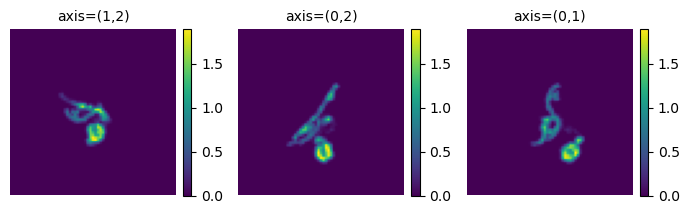

In [3]:
plots.orthogonal_2D_projection_plot(v)

Vol 0 alignment =  0.09791207313537598
Vol 5 alignment =  0.09501218795776367
Vol 10 alignment =  0.0957188606262207
Vol 16 alignment =  0.09711670875549316
Vol 21 alignment =  0.09756803512573242
Vol 27 alignment =  0.09706687927246094
Vol 32 alignment =  0.0977318286895752
Vol 38 alignment =  0.09630489349365234
Vol 43 alignment =  0.09679007530212402
Vol 49 alignment =  0.09765911102294922
  L2:  [0.         0.8100364  0.8900205  0.95724297 0.9757023  0.9940309
 0.9956678  1.         0.9978418  0.9996276 ]
  SW:  [0.         0.11716161 0.23280388 0.36866132 0.47808118 0.60407641
 0.7037224  0.81624606 0.90345241 1.        ]
RFSW:  [0.         0.47501446 0.5572192  0.65424539 0.71635202 0.79805215
 0.86434881 0.88805464 0.93367045 1.        ]


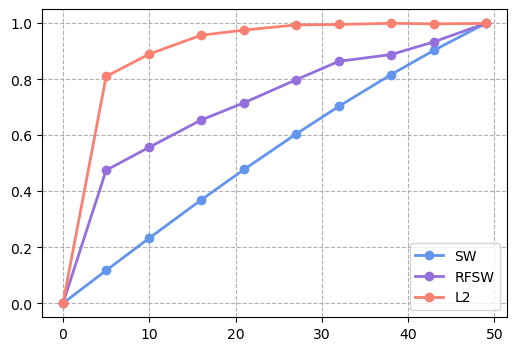

In [5]:
# ### EV: first try without rotation

# distances_sw = {}
# distances_rfsw = {}
# distances_l2 = {}

# sinthetas = np.sin(thetas)[np.newaxis, np.newaxis, :]

# F = signals.Signal(F, d=3).preprocess_signals()[0]
# F_t = transforms.Transform(F, d=3).inverse_cdf_transform()[0]
# F_t_norm = np.sqrt(np.sum(F_t**2 * sinthetas))

# F_tp, F_tn = transforms.Transform(F, d=3, apply_ramp=True).signed_inverse_cdf_transform()

# for k in range(n_vols):

#     G = het_vols[k]
    
#     t = time.time()

#     G = signals.Signal(G, d=3).preprocess_signals()[0]
#     distances_l2[k] = np.linalg.norm(F - G)
    
#     G_t = transforms.Transform(G, d=3).inverse_cdf_transform()[0]
#     G_t_norm = np.sqrt(np.sum(G_t**2 * sinthetas))
#     distances_sw[k] = distances.sliced_distance_3d(F_t, G_t, sinthetas)

#     G_tp, G_tn = transforms.Transform(G, d=3, apply_ramp=True).signed_inverse_cdf_transform()
#     G_tp_norm = np.sqrt(np.sum(G_tp**2 * sinthetas))
#     G_tn_norm = np.sqrt(np.sum(G_tn**2 * sinthetas))
#     distances_rfsw[k] = distances.signed_sliced_distance_3d(F_tp[0], G_tp[0], F_tn[0], G_tn[0], sinthetas)
    
#     print("Vol {} alignment = ".format(vol_idx[k]), time.time() - t)

# dists_l2 = np.array([dist for k, dist in distances_l2.items()])
# dists_sw = np.array([dist for k, dist in distances_sw.items()])
# dists_rfsw = np.array([dist for k, dist in distances_rfsw.items()])

# dists_l2 = np.sqrt( dists_l2 / np.amax(dists_l2) )
# dists_sw = np.sqrt( dists_sw / np.amax(dists_sw) )
# dists_rfsw = np.sqrt( dists_rfsw / np.amax(dists_rfsw) )

# print('  L2: ', dists_l2)
# print('  SW: ', dists_sw)
# print('RFSW: ', dists_rfsw)

# plt.figure(figsize=(6,4))
# plt.plot(vol_idx[:], dists_sw, color='cornflowerblue', marker='o', linewidth=2, label='SW')
# plt.plot(vol_idx[:], dists_rfsw, color='mediumpurple', marker='o', linewidth=2, label='RFSW')
# plt.plot(vol_idx[:], dists_l2, color='salmon', marker='o', linewidth=2, label='L2')
# plt.grid(which='major', linestyle='--')
# plt.legend()
# plt.show()

In [ ]:
### EV: Now test with rotation

### 1) preprocess

np.random.seed(0)

metric = 'distance'

# omegas = np.deg2rad(np.random.randint(0, 360, n_vols))
# betas = np.deg2rad(np.random.randint(0, 180, n_vols))
# alphas = np.deg2rad(np.random.randint(0, 360, n_vols))

het_vols_rotated = []

print(np.amin(het_vols[0]), np.amax(het_vols[0]), np.sum(het_vols[0]))
# print(np.sum(np.where(het_vols[0] < 0, het_vols[0], 0)), np.sum(np.where(het_vols[0] > 0, het_vols[0], 0)))
print('\n')

for idx in range(n_vols):
    
    # o, b, a = omegas[idx], betas[idx], alphas[idx]
    # rot_vol = transforms.rotate_voxel_zyz_fourier(het_vols[v_idx], o, b, a)

    ### EV: rotations that should not cause negative from interpolation
    ###     don't need to renormalize signal 
    ###     do either of these cause reflection?
    # rot_vol = het_vols[idx][::-1, :, ::-1]
    # rot_vol = np.rot90(het_vols[idx])  

    ### EV: or no rotation
    rot_vol = het_vols[idx]
    
    # print(np.amin(rot_vol), np.amax(rot_vol), np.sum(rot_vol))
    # print(np.sum(np.where(rot_vol < 0, rot_vol, 0)), np.sum(np.where(rot_vol > 0, rot_vol, 0)))
    # print('\n')
    # rot_vol = np.where(rot_vol<0, 0, rot_vol)
    # rot_vol -= np.amin(rot_vol)
    # rot_vol = signals.Signal(rot_vol, d=3).preprocess_signals()[0]
    # print(np.amin(rot_vol), np.amax(rot_vol), np.sum(rot_vol))
    
    het_vols_rotated.append(rot_vol)

het_vols_rotated = np.array(het_vols_rotated)


sinthetas = np.sin(thetas)[np.newaxis, np.newaxis, :]
# sinthetas = np.ones(M)

fle = fle_3d.FLEBasis3D(M, M, 1e-6, max_l=max_l, mode="complex", force_real="True")

print(np.amin(F), np.amax(F), np.sum(F))

F_t = transforms.Transform(F, d=3).inverse_cdf_transform()[0]
F_tp, F_tn = transforms.Transform(F, d=3, apply_ramp=True).signed_inverse_cdf_transform()

F_norm = np.linalg.norm(F)
F_t_norm = np.linalg.norm(F_t*sinthetas)
F_tp_norm, F_tn_norm = np.linalg.norm(F_tp[0]*sinthetas), np.linalg.norm(F_tn[0]*sinthetas)

In [ ]:
plots.orthogonal_2D_projection_plot(het_vols[0])
plots.orthogonal_2D_projection_plot(het_vols_rotated[0])
plots.orthogonal_2D_projection_plot(het_vols[0] - het_vols_rotated[0])

In [ ]:
# np.allclose(F, het_vols_rotated[0][::-1, :, ::-1])
# np.allclose(F, np.rot90(het_vols_rotated[0], -1))

In [ ]:
### 2) compute distances

print(metric.upper(), '\n')

distances_l2, distances_sw, distances_rfsw = [], [], []
rot_matrices_l2, rot_matrices_sw, rot_matrices_rfsw = {}, {}, {}
het_vols_aligned_l2, het_vols_aligned_sw, het_vols_aligned_rfsw = {}, {}, {}


for k in range(n_vols):
    
    G = het_vols_rotated[k].copy()
    G_norm = np.linalg.norm(G)

    print('F: ', np.amin(F), np.amax(F), np.sum(F))
    print('G: ', np.amin(G), np.amax(G), np.sum(G))

    t = time.time()
    
    
    # ###
    # ### 1) COMPUTE EUCLIDEAN DISTANCE
    # ###

    # c = alignments.align_l2(np.flip(F, axis=2), np.flip(G, axis=2), fle)
    # # c = alignments.align_l2(F, G, fle)

    # if metric == 'correlation':
    #     c = c / (F_norm * G_norm)  ### EV: FIX THIS - normalize for scaling / comparison ???
    #     distances_l2.append(np.amax(c))
    #     R_est = alignments.alignment_matrix_from_distances(c, corr=True)

    # elif metric == 'distance':
    #     dists = (F_norm**2 + G_norm**2) * dV - 2*c
    #     distances_l2.append(np.amin(dists))
    #     R_est = alignments.alignment_matrix_from_distances(dists, corr=False)        

    # rot_matrices_l2[vol_idx[k]] = R_est
    
    # print("Vol {} alignment L2   = ".format(vol_idx[k]), time.time() - t)
    
    # o_est, b_est, a_est = Rotation.from_matrix(R_est.T).as_euler('zyz')
    # het_vols_aligned_l2[vol_idx[k]] = transforms.rotate_voxel_zyz_fourier(G, -a_est, -b_est, -o_est)

    
    ###
    ### 2) COMPUTE SLICED 2-WASSERSTEIN DISTANCE
    ###
    
    t = time.time()

    G_t = transforms.Transform(G, d=3).inverse_cdf_transform()[0]
    G_t_norm = np.linalg.norm(G_t*sinthetas)
    
    c = alignments.fast_rotational_correlation(F_t, G_t, fle)
    print(np.amax(c))

    if metric == 'correlation':
        c = c / (F_t_norm * G_t_norm)
        distances_sw.append(np.amax(c))
        R_est = alignments.alignment_matrix_from_distances(c, corr=True)
    
    elif metric == 'distance':
        dists = ( (F_t_norm**2 + G_t_norm**2) * dVsphere - 2*c ) / (4*np.pi)
        distances_sw.append(np.amin(dists))
        R_est = alignments.alignment_matrix_from_distances(dists, corr=False)
        
    rot_matrices_sw[vol_idx[k]] = R_est

    print("Vol {} alignment SW   = ".format(vol_idx[k]), time.time() - t)

    o_est, b_est, a_est = Rotation.from_matrix(R_est.T).as_euler('zyz')
    het_vols_aligned_sw[vol_idx[k]] = transforms.rotate_voxel_zyz_fourier(G, -a_est, -b_est, -o_est)

    
    # ###
    # ### 2) COMPUTE RAMP FILTERED SLICED 2-WASSERSTEIN DISTANCE
    # ###    

    # t = time.time()
    
    # G_tp, G_tn = transforms.Transform(G, d=3, apply_ramp=True).signed_inverse_cdf_transform()
    # G_tp_norm, G_tn_norm = np.linalg.norm(G_tp[0]*sinthetas), np.linalg.norm(G_tn[0]*sinthetas)
       
    # cp = alignments.fast_rotational_correlation(F_tp[0], G_tp[0], fle)
    # cn = alignments.fast_rotational_correlation(F_tn[0], G_tn[0], fle)
    # print(np.amax(cp), np.amax(cn))
    
    # if metric == 'correlation':
    #     cp = cp / (F_tp_norm * G_tp_norm)
    #     cn = cn / (F_tn_norm * G_tn_norm) 
    #     c = (cp + cn) / 2
    #     distances_rfsw.append(np.amax(c))
    #     R_est = alignments.alignment_matrix_from_distances(c, corr=True)
    
    # elif metric == 'distance':
    #     dists_p = ( (F_tp_norm**2 + G_tp_norm**2) * dVsphere - 2*cp ) / (4*np.pi)
    #     dists_n = ( (F_tn_norm**2 + G_tn_norm**2) * dVsphere - 2*cn ) / (4*np.pi)
    #     dists = (dists_p + dists_n) / 2
    #     distances_rfsw.append(np.amin(dists))
    #     R_est = alignments.alignment_matrix_from_distances(dists, corr=False)
        
    # rot_matrices_rfsw[vol_idx[k]] = R_est

    # print("Vol {} alignment RFSW = ".format(vol_idx[k]), time.time() - t)

    # o_est, b_est, a_est = Rotation.from_matrix(R_est.T).as_euler('zyz')
    # het_vols_aligned_rfsw[vol_idx[k]] = transforms.rotate_voxel_zyz_fourier(G, -a_est, -b_est, -o_est)

    print("\n")


distances_l2 = np.array(distances_l2)
distances_sw = np.array(distances_sw)
distances_rfsw = np.array(distances_rfsw)

In [ ]:
print('  L2: ', distances_l2)
print('  SW: ', distances_sw)
print('RFSW: ', distances_rfsw)

In [ ]:
### EV: need additional scale correction? this is true for distance and correlation, right?

###     voxel scaling ? volume element ?

# dists_l2 = distances_l2 
dists_sw = distances_sw
# dists_rfsw = distances_rfsw

### EV: force distances to same scale (so scores can only be compared within metric)

if metric == 'distance':
    # dists_l2 = np.sqrt( dists_l2 / np.amax(dists_l2) ) 
    dists_sw = np.sqrt( dists_sw / np.amax(dists_sw) )
    # dists_rfsw = np.sqrt( dists_rfsw / np.amax(dists_rfsw) )


### or should I normalize the correlations here ? ### should this work?
### <f, g_i> / ||f|| ||g_i||

# if metric == 'correlation':
#    pass

In [ ]:
plt.figure(figsize=(6,4))

# plt.plot(vol_idx[:], dists_l2, color='salmon', marker='o', linewidth=2, label='L2')
# plt.plot(vol_idx[:], dists_sw, color='cornflowerblue', marker='o', linewidth=2, label='SW')
# plt.plot(vol_idx[:], dists_rfsw, color='mediumpurple', marker='o', linewidth=2, label='RFSW')

# plt.plot(vol_idx[:], distances_l2, color='salmon', marker='o', linewidth=2, label='L2')
plt.plot(vol_idx[:], distances_sw, color='cornflowerblue', marker='o', linewidth=2, label='SW')
# plt.plot(vol_idx[:], distances_rfsw, color='mediumpurple', marker='o', linewidth=2, label='RFSW')

plt.grid(which='major', linestyle='--')
# plt.ylim(-0.05, 1.05)
plt.legend(loc='lower right')
plt.show()

In [ ]:
# for k, v in het_vols.items():
#     print('\t', k, '\t', 'unrotated')
#     plots.orthogonal_2D_projection_plot(het_vols[0] - het_vols[k])


# for k, v in het_vols_rotated.items():
#     print('\t', k, '\t', 'rotated')
#     plots.orthogonal_2D_projection_plot(het_vols[0] - het_vols_rotated[k])


for k, v in het_vols_aligned_l2.items():
    print('\t', k, '\t', 'aligned l2')
    plots.orthogonal_2D_projection_plot(F - v)


# for k, v in het_vols_aligned_sw.items():
#     print('\t', k, '\t', 'aligned sw')
#     plots.orthogonal_2D_projection_plot(F - v)


# for k, v in het_vols_aligned_rfsw.items():
#     print('\t', k, '\t', 'aligned rfsw')
#     plots.orthogonal_2D_projection_plot(F - v)

In [ ]:
### I think the ordering of the angles from rotmat_to_euler_zyz should be flipped?

for k, idx in enumerate(vol_idx):
    print(idx,':')
    # print('  GT: ', np.rad2deg([omegas[k], betas[k], alphas[k]]))
    print('  L2: ', np.round( np.rad2deg(transforms.rotmat_to_euler_zyz(rot_matrices_l2[idx].T)), 1 ))
    print('  SW: ', np.round( np.rad2deg(transforms.rotmat_to_euler_zyz(rot_matrices_sw[idx].T)), 1 ))
    print('RFSW: ', np.round( np.rad2deg(transforms.rotmat_to_euler_zyz(rot_matrices_rfsw[idx].T)), 1 ))
    print('\n')

In [ ]:
# # # The downsampled volume
# with mrcfile.new('Output/ref_vol_65.mrc', overwrite=True) as mrc:
#     mrc.set_data(het_vols[0].astype('float32'))

# with mrcfile.new('Output/vol_21_rot_aligned_rfsw.mrc', overwrite=True) as mrc:
#     mrc.set_data(het_vols_aligned_rfsw[4].astype('float32'))

# with mrcfile.new('Output/vol_21_rot_aligned_sw.mrc', overwrite=True) as mrc:
#     mrc.set_data(het_vols_aligned_sw[4].astype('float32'))

# with mrcfile.new('Output/vol_21_rot_aligned_l2.mrc', overwrite=True) as mrc:
#     mrc.set_data(het_vols_aligned_l2[4].astype('float32'))
 

# with mrcfile.new('Output/vol_49_rot_aligned_rfsw.mrc', overwrite=True) as mrc:
#     mrc.set_data(het_vols_aligned_rfsw[9].astype('float32'))

# with mrcfile.new('Output/vol_49_rot_aligned_sw.mrc', overwrite=True) as mrc:
#     mrc.set_data(het_vols_aligned_sw[9].astype('float32'))

# with mrcfile.new('Output/vol_49_rot_aligned_l2.mrc', overwrite=True) as mrc:
#     mrc.set_data(het_vols_aligned_l2[9].astype('float32'))

In [ ]:
plt.plot(thetas, sinthetas.flatten(), 'p--')

In [ ]:
sinthetas.shape

In [ ]:
Z = np.ones((65,65,65))

In [ ]:
plt.imshow(np.sum(Z * sinthetas, axis=0))

In [ ]:
F_t_norm, G_t_norm

In [ ]:
plots.orthogonal_2D_slice_plot(F_t)
plots.orthogonal_2D_slice_plot(G_t)

In [ ]:
distances_sw

In [ ]:
F_t_norm

In [ ]:
c